In [60]:
import matplotlib.pyplot as plt
import torch
import numpy as np
from dataset import F1DS
from torchvision import transforms
from torch.utils.data import Dataset, DataLoader, random_split
from main import CNNModule
import pandas as pd
data_test_transform = transforms.Compose([
    transforms.ToTensor(),
])
csv_test = 'test.csv'
test_dataset = F1DS(csv_test, seq_len=50, transform=data_test_transform)
test_loader = DataLoader(test_dataset, batch_size=1, shuffle=True, num_workers=0, pin_memory=True)

In [2]:
PATH = "/home/iramirez/Pytorch/neuralpilot/logs/ltc/version_3/checkpoints/epoch=2409-step=24100.ckpt"
model = CNNModule.load_from_checkpoint(PATH)
model.model = model.model.eval()

In [3]:
len(test_loader)

100

In [64]:
x, y = next(iter(test_loader))

In [11]:
x.shape

torch.Size([1, 128, 3, 15, 20])

In [65]:
with torch.no_grad():
    y_hat_list = []
    y_hat = 0.
    alpha = 1
    for i in range(x.size(1)):
        y_hat_new = model(x[:,i:i+1,...].to("cuda:2")).cpu().numpy()
        # y_hat_new = model.model(x[:,i:i+1,...].to("cuda:2"), n_iter=2).cpu().numpy()
        y_hat_list.append(alpha*y_hat_new + (1-alpha)*y_hat)
        # y_hat_list.append(0.*y_hat_new)
        y_hat = y_hat_list[-1]
y_hat = np.concatenate(y_hat_list, 1)



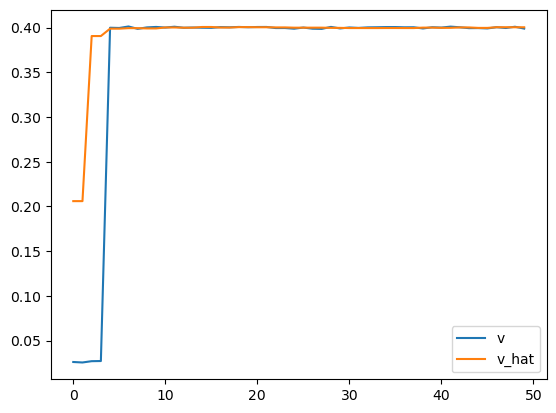

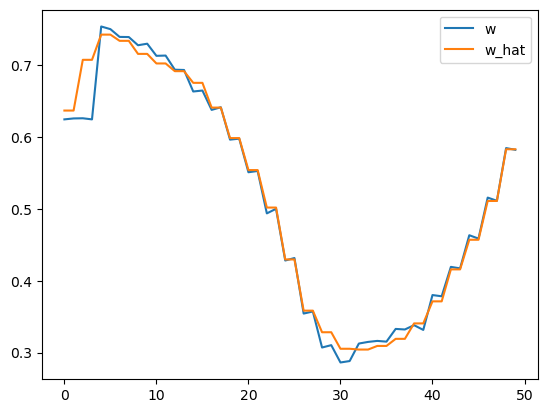

In [66]:
y_v_df = pd.DataFrame(np.concatenate([y.numpy()[0,:,0:1], y_hat[0,:,0:1]],-1), columns=['v', 'v_hat'])
y_w_df = pd.DataFrame(np.concatenate([y.numpy()[0,:,1:], y_hat[0,:,1:]],-1), columns=['w', 'w_hat'])
y_v_df.plot()
y_w_df.plot()
plt.show()

In [21]:
seq_len = 32
i = 4
x[:,max(0, i-seq_len+1):i+1,...].shape

torch.Size([1, 5, 3, 12, 16])

In [23]:
with torch.no_grad():
    y_hat_list = []
    y_hat = 0.
    alpha = 1
    seq_len = 5
    for i in range(x.size(1)):
        y_hat_new = model(x[:,max(0, i-seq_len+1):i+1,...].to("cuda:2")).cpu().numpy()[:,-1:,...]
        # print(y_hat_new.shape)
        y_hat_list.append(alpha*y_hat_new + (1-alpha)*y_hat)
        # y_hat_list.append(0.*y_hat_new)
        y_hat = y_hat_list[-1]
y_hat = np.concatenate(y_hat_list, 1)

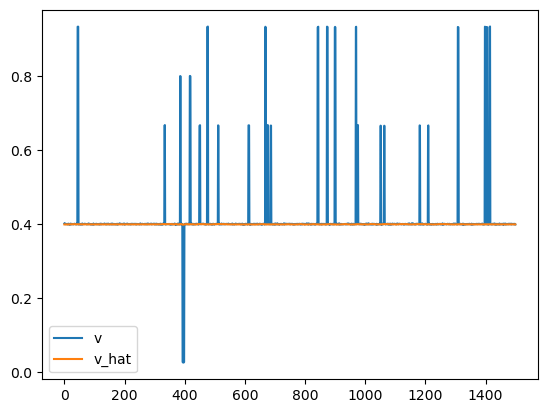

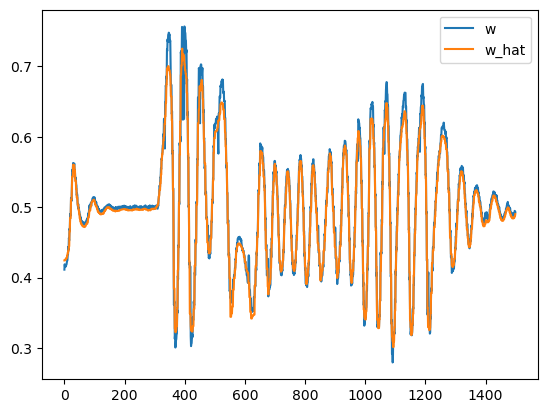

In [24]:
y_v_df = pd.DataFrame(np.concatenate([y.numpy()[0,:,0:1], y_hat[0,:,0:1]],-1), columns=['v', 'v_hat'])
y_w_df = pd.DataFrame(np.concatenate([y.numpy()[0,:,1:], y_hat[0,:,1:]],-1), columns=['w', 'w_hat'])
y_v_df.plot()
y_w_df.plot()
plt.show()

In [13]:
import matplotlib.animation
import matplotlib.pyplot as plt
import numpy as np
plt.rcParams["animation.html"] = "jshtml"
plt.rcParams['figure.dpi'] = 150  
plt.ioff()
fig, ax = plt.subplots()

def animate(t):
    plt.cla()
    plt.imshow(x[0,t,...].permute(1,2,0).numpy())
    # plt.xlim(0,10)
    # plt.draw()
matplotlib.animation.FuncAnimation(fig, animate, frames=200)

In [8]:
total = []
for parameter in model.parameters():
    total.append(np.prod(parameter.shape))
print(sum(total))

54082
